# 01 · Auditoría de datos: v0.2 vs v3

**Objetivo.** Medir con los datos reales qué cambió entre el ETL de la v0.2 y el de la v3, y separar cada efecto:

1. **Estado de calidad v3**: qué marcó la validación y por qué.
2. **Recorte (winsorización) de v0.2**: cuánto subestimaba la cola extrema.
3. **Dividendos**: cuánto retorno perdía v0.2 al usar el cierre sin ajustar.
4. **Portafolio**: por qué el VaR al 5 % casi no cambió (datos, calendario y ventana).
5. **Días marcados**: revisión de los flags, incluido el detalle de ETH.

**Entradas**
- `data/legacy_v02/raw/*.csv`: datos v0.2 (Yahoo Finance, recortados).
- `data/processed/*.csv`: datos v3 (Tiingo y Coinbase, validados).
- `artifacts/data_quality/latest.json`: informe del último ETL.

**Requisito:** haber corrido `python -m alphaquant.data.pipeline`.

## Glosario

Los términos que aparecen en las tablas de este notebook, agrupados por tema. Los nombres entre `comillas` son columnas o flags que salen tal cual en los datos.

### A · Datos de precio

| Término | Qué significa |
|---|---|
| OHLCV | Open, High, Low, Close, Volume: apertura, máximo, mínimo, cierre y volumen del día. |
| Vela diaria | El resumen OHLCV de un día. En cripto va de 00:00 a 24:00 UTC. |
| `close` | Precio de cierre sin ajustar: el que se vio en el mercado ese día. |
| `adj_close` | Cierre ajustado por splits y dividendos. Sirve para medir el retorno real de quien tuvo el activo. |
| `dividend` | Dividendo en efectivo por acción pagado ese día (0 si no hubo). |
| `split_factor` | Razón del split de acciones ese día (1 si no hubo). Un split 4 a 1 baja el precio crudo 75 % sin que nadie pierda dinero. |
| `volume` | Unidades negociadas ese día (acciones, o monedas en cripto). No son dólares: para eso se multiplica por el precio. |
| `ret` | Retorno logarítmico total del día: ln(adj_close de hoy / adj_close de ayer). Incluye dividendos. |
| `ret_price` | Igual que `ret` pero sin dividendos (solo precio). Existe solo en este notebook, para aislar el efecto de los dividendos. |
| Retorno logarítmico vs simple | Simple = e^ret − 1. Son casi iguales si el movimiento es chico, pero difieren si es grande: −0.30 en log equivale a −26 % simple. |
| Sesión NYSE | Día en que abre la bolsa de Nueva York (sin fines de semana ni festivos). Cripto opera todos los días. |

### B · Calidad de datos

| Término | Qué significa |
|---|---|
| PASS / WARN / FAIL | PASS: sin observaciones. WARN: hay días marcados para revisar y el ticker se publica igual. FAIL: rompe el contrato de datos o le faltan demasiadas fechas, y no se publica. |
| Contrato de datos | Reglas mínimas que toda fila debe cumplir: tipos correctos, sin nulos, precios mayores a 0, fechas únicas y ordenadas. Se valida con Pandera. |
| `faltantes` | Fechas en que debía haber una fila y no la hay. Da FAIL si faltan más del 1 % o más de 3 seguidas. |
| Flag | Marca que se agrega a un día sospechoso. El día no se borra ni se corrige. |
| `flag_outlier` | Retorno atípico: su z robusto supera 8 en valor absoluto. Se calcula como (retorno − mediana) / (1.4826 × MAD) con los 252 días anteriores, así que solo mira el pasado. |
| `flag_jump_no_action` | Salto de más de 25 % en el precio sin ajustar en un solo día, sin dividendo ni split que lo explique. Está para detectar splits que el proveedor olvidó registrar. Solo acciones y ETFs. |
| `flag_stale` | Precio congelado: mismo cierre 3 sesiones seguidas (acciones) o 2 días seguidos (cripto), o máximo igual a mínimo con volumen mayor a 0. |
| `flag_ohlc` | Vela imposible: el mínimo no es el menor, o el máximo no es el mayor, entre apertura, cierre, mínimo y máximo. |
| `flag_zero_volume` | Volumen igual a 0 ese día. |
| `flag_adj_inconsistent` | El cociente adj_close / close cambió sin que hubiera dividendo ni split. Delata un ajuste mal calculado por el proveedor. |
| `flag_non_session` | Fila en una fecha en que la bolsa estaba cerrada. Se excluye de los datos procesados. |
| `flag_any` | Verdadero si el día tiene al menos un flag. |
| Evento real vs error | Un flag no dice que el dato esté mal. Un crash conocido (COVID) es un evento real y se conserva. Un error se confirma contrastando con otra fuente. |
| Falso positivo | Día marcado que en realidad es correcto. |
| Mediana y MAD | La MAD es la mediana de las distancias a la mediana. Miden centro y dispersión sin que los extremos las distorsionen, a diferencia del promedio y la desviación estándar. |
| Look-ahead | Usar información del futuro en un cálculo. Ejemplo: el recorte de v0.2 usaba cuantiles de toda la muestra. |

### C · Riesgo y comparación v0.2 vs v3

| Término | Qué significa |
|---|---|
| VaR 5 % | Pérdida diaria que solo se supera en el 5 % de los días (1 de cada 20). Se muestra como número positivo: 0.02 = 2 %. |
| CVaR 5 % | Promedio de la pérdida en esos peores días. Siempre es mayor que el VaR. |
| VaR 1 % / CVaR 1 % | Lo mismo con el 1 % peor de los días. Es la cola extrema. |
| VaR histórico | Se calcula directamente de los retornos pasados, sin suponer ninguna distribución. |
| Max drawdown (`max_dd`) | Mayor caída desde un máximo hasta el mínimo siguiente de la curva de valor. 0.41 = 41 %. |
| Sharpe | Retorno promedio dividido por su volatilidad, anualizado (252 días) y con tasa libre de riesgo 0. Mide retorno por unidad de riesgo. |
| Winsorización (recorte) | Reemplazar los valores extremos por un límite. v0.2 lo hacía y escondía los peores días. |
| `subestim_%` | 100 × (1 − valor de v0.2 / valor de v3). Positivo significa que v0.2 mostraba menos riesgo del real. |
| Calendario común | Usar solo las fechas en que todos los activos tienen retorno, para que los cálculos entre activos sean comparables. |
| Agregación de cripto al lunes | Sumar los retornos logarítmicos de sábado, domingo y lunes de cripto en el lunes, para alinearlos con las acciones sin perder el riesgo del fin de semana. |

In [13]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from alphaquant.core import paths
from alphaquant.core.config import load_config
from alphaquant.data.calendars import aggregate_crypto_to_equity_sessions, expected_dates, is_crypto
from alphaquant.risk.portfolio_analytics import (
    historical_cvar,
    historical_var,
    max_drawdown,
    portfolio_returns,
    sharpe_ratio,
)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

LEGACY_DIR = paths.data_dir() / "legacy_v02" / "raw"
PROCESSED_DIR = paths.processed_dir()
REPORT_FILE = paths.artifacts_dir() / "data_quality" / "latest.json"
TICKERS = load_config()["tickers"]

for p in (LEGACY_DIR, PROCESSED_DIR, REPORT_FILE):
    assert p.exists(), f"Falta {p}: corre primero el ETL (y la migracion v3 para legacy_v02)"
print("Raiz del proyecto:", paths.project_root())
print("Tickers:", len(TICKERS))

Raiz del proyecto: C:\Users\Carlo\Downloads\AQR\AlphaQuant_repo
Tickers: 18


## Carga de datos

- **v0.2**: `ret` es el retorno log del cierre **sin ajustar por dividendos** y **recortado** a los cuantiles 0.1 %/99.9 % de toda la muestra.
- **v3**: `ret` es el retorno log **total** (desde `adj_close`, con dividendos) y **sin recortes**.

Para aislar efectos se calcula además `ret_price` en v3: el retorno de precio ajustado solo por splits, sin dividendos. Es el equivalente "limpio" de lo que v0.2 intentaba medir.

In [14]:
def load_legacy(ticker: str) -> pd.DataFrame:
    df = pd.read_csv(LEGACY_DIR / f"{ticker}_1d.csv", usecols=["Datetime", "Close", "AdjClose", "ret"])
    df["date"] = pd.to_datetime(df["Datetime"], utc=True).dt.tz_localize(None).dt.normalize()
    df = df.drop_duplicates("date").set_index("date").sort_index()
    return df.rename(columns={"Close": "close", "AdjClose": "adj_close"})[["close", "adj_close", "ret"]]


def load_v3(ticker: str) -> pd.DataFrame:
    df = pd.read_csv(PROCESSED_DIR / f"{ticker}_1d.csv", parse_dates=["date"]).set_index("date")
    # F_t = producto de los splits POSTERIORES a t: lleva el precio crudo a la base actual.
    future_splits = df["split_factor"][::-1].cumprod()[::-1].shift(-1).fillna(1.0)
    df["ret_price"] = np.log(df["close"] / future_splits).diff()
    return df


legacy = {t: load_legacy(t) for t in TICKERS}
v3 = {t: load_v3(t) for t in TICKERS}

pd.DataFrame({
    t: {"v0.2 desde": legacy[t].index.min().date(), "v0.2 hasta": legacy[t].index.max().date(),
        "v0.2 filas": len(legacy[t]), "v3 desde": v3[t].index.min().date(),
        "v3 hasta": v3[t].index.max().date(), "v3 filas": len(v3[t])}
    for t in TICKERS
}).T

,v0.2 desde,v0.2 hasta,v0.2 filas,v3 desde,v3 hasta,v3 filas
SPY,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
QQQ,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
DIA,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
IWM,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
AAPL,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
MSFT,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
NVDA,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
AMZN,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
GOOGL,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954
META,2015-01-02,2026-08-31,2932,2015-01-05,2026-10-02,2954


## 1 · Estado de calidad v3

Resumen del informe del ETL. Un **WARN** no es un error: significa que hay días marcados para revisar. Un ticker en **FAIL** no se publica.

In [15]:
report = json.loads(REPORT_FILE.read_text(encoding="utf-8"))
print(f"Corrida {report['run_id']} | estado global: {report['overall']}")

rows = []
for t in report["tickers"]:
    st = t.get("stats") or {}
    flags = {k.replace("flag_", ""): v for k, v in (st.get("flags") or {}).items()}
    rows.append({"ticker": t["ticker"], "fuente": t["provider"], "estado": t["status"],
                 "desde": st.get("first_date"), "faltantes": st.get("missing_dates"), **flags})
quality = pd.DataFrame(rows).set_index("ticker")
quality

Corrida 20261005T172631Z | estado global: WARN


,fuente,estado,desde,faltantes,non_session,ohlc,zero_volume,stale,outlier,jump_no_action,adj_inconsistent
ticker,,,,,,,,,,,
SPY,tiingo,WARN,2015-01-02,0,0,0,0,0,17,0,0
QQQ,tiingo,WARN,2015-01-02,0,0,0,0,0,9,0,0
DIA,tiingo,WARN,2015-01-02,0,0,0,0,0,17,0,0
IWM,tiingo,WARN,2015-01-02,0,0,0,0,0,5,0,0
AAPL,tiingo,WARN,2015-01-02,0,0,0,0,0,2,0,0
MSFT,tiingo,WARN,2015-01-02,0,0,0,0,0,8,0,0
NVDA,tiingo,WARN,2015-01-02,0,0,0,0,0,5,1,0
AMZN,tiingo,WARN,2015-01-02,0,0,0,0,1,3,0,0
GOOGL,tiingo,WARN,2015-01-02,0,0,0,0,0,3,0,0


## 2 · Efecto del recorte de v0.2

Se compara `ret` de v0.2 contra `ret_price` de v3, **en las mismas fechas**, para medir solo el efecto del recorte.

Dos advertencias para leer la tabla:
- Las fuentes son distintas (Yahoo vs Tiingo/Coinbase). Por eso hay pequeñas diferencias diarias que no vienen del recorte. Se cuentan como "días distintos" las diferencias mayores a 0.1 %.
- En cripto, la diferencia mezcla el recorte con el cambio de fuente: Yahoo agrega varios exchanges y Coinbase es uno solo.

**Qué esperar:** el recorte afectaba al 0.1 % de los días más extremos de cada lado, así que debe notarse en el **peor día** y en el **VaR/CVaR al 1 %**, y casi nada en el VaR al 5 %.

In [16]:
def tail(r: pd.Series) -> dict:
    return {"peor": r.min(), "VaR5": historical_var(r, 0.05), "CVaR5": historical_cvar(r, 0.05),
            "VaR1": historical_var(r, 0.01), "CVaR1": historical_cvar(r, 0.01)}


rows = []
for t in TICKERS:
    old = legacy[t]["ret"].dropna()
    new = v3[t]["ret_price"].dropna()
    idx = old.index.intersection(new.index)
    o, n = tail(old.loc[idx]), tail(new.loc[idx])
    rows.append({
        "ticker": t, "dias": len(idx),
        "dias_distintos": int(((old.loc[idx] - new.loc[idx]).abs() > 1e-3).sum()),
        "peor_v02": o["peor"], "peor_v3": n["peor"],
        "VaR5_v02": o["VaR5"], "VaR5_v3": n["VaR5"],
        "CVaR1_v02": o["CVaR1"], "CVaR1_v3": n["CVaR1"],
        "subestim_CVaR1_%": 100 * (1 - o["CVaR1"] / n["CVaR1"]),
        "subestim_VaR5_%": 100 * (1 - o["VaR5"] / n["VaR5"]),
    })
clipping = pd.DataFrame(rows).set_index("ticker")
clipping

,dias,dias_distintos,peor_v02,peor_v3,VaR5_v02,VaR5_v3,CVaR1_v02,CVaR1_v3,subestim_CVaR1_%,subestim_VaR5_%
ticker,,,,,,,,,,
SPY,2930,11,-0.0618,-0.1159,0.0168,0.0168,0.0435,0.0472,7.8571,0.0000
QQQ,2930,7,-0.0647,-0.1276,0.0223,0.0223,0.0485,0.0519,6.5343,-0.0000
DIA,2930,6,-0.0713,-0.1365,0.0157,0.0157,0.0438,0.0475,7.7039,-0.0002
IWM,2930,9,-0.0822,-0.1423,0.0213,0.0213,0.0504,0.0542,6.9871,-0.0001
AAPL,2930,9,-0.0975,-0.1377,0.0275,0.0275,0.0667,0.0685,2.6344,-0.0000
MSFT,2930,9,-0.0973,-0.1595,0.0269,0.0269,0.0612,0.0636,3.8033,0.0001
NVDA,2930,7,-0.1514,-0.2077,0.0453,0.0453,0.0991,0.1039,4.6097,0.0001
AMZN,2930,7,-0.0884,-0.1514,0.0311,0.0311,0.0708,0.0733,3.2929,0.0001
GOOGL,2930,9,-0.0863,-0.1237,0.0274,0.0274,0.0635,0.0655,3.0776,0.0001


Subestimacion promedio del CVaR 1 %: 5.8 %
Subestimacion promedio del VaR 5 %:  0.4 %


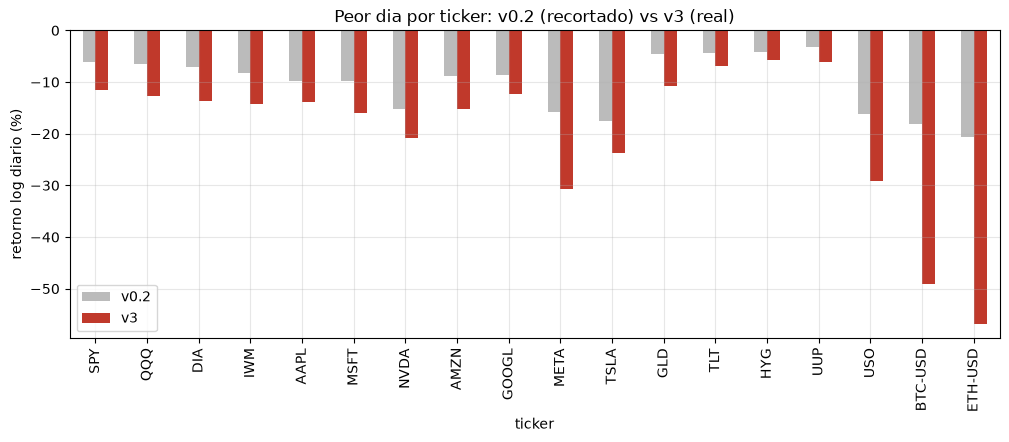

In [17]:
print(f"Subestimacion promedio del CVaR 1 %: {clipping['subestim_CVaR1_%'].mean():.1f} %")
print(f"Subestimacion promedio del VaR 5 %:  {clipping['subestim_VaR5_%'].mean():.1f} %")

ax = clipping[["peor_v02", "peor_v3"]].mul(100).plot.bar(figsize=(12, 4), color=["#bbbbbb", "#c0392b"])
ax.set_title("Peor dia por ticker: v0.2 (recortado) vs v3 (real)")
ax.set_ylabel("retorno log diario (%)")
ax.legend(["v0.2", "v3"])
plt.show()

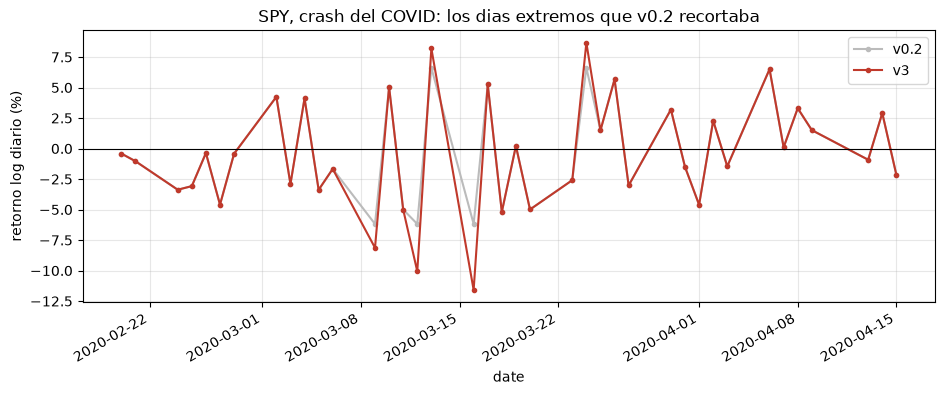

,v0.2,v3
date,,
2020-03-09,-6.1796,-8.1313
2020-03-12,-6.1796,-10.0569
2020-03-13,6.6198,8.2028
2020-03-16,-6.1796,-11.5887
2020-03-24,6.6198,8.6731


In [18]:
window = slice("2020-02-20", "2020-04-15")
spy = pd.DataFrame({"v0.2": legacy["SPY"]["ret"], "v3": v3["SPY"]["ret_price"]}).loc[window].mul(100)

ax = spy.plot(marker="o", ms=3, color=["#bbbbbb", "#c0392b"])
ax.axhline(0, color="black", lw=0.8)
ax.set_title("SPY, crash del COVID: los dias extremos que v0.2 recortaba")
ax.set_ylabel("retorno log diario (%)")
plt.show()
spy[(spy["v0.2"] - spy["v3"]).abs() > 0.1]

## 3 · Efecto de los dividendos

v0.2 calculaba el retorno con el cierre sin ajustar: el día del pago, el precio cae por el monto del dividendo y eso se registraba como pérdida. v3 usa el precio ajustado, es decir, el retorno total.

La diferencia anual entre `ret` (total) y `ret_price` (solo precio) es el rendimiento por dividendos que v0.2 no contaba. Las cripto no pagan dividendos, así que su diferencia debe ser 0.

In [19]:
rows = []
for t in TICKERS:
    d = v3[t].dropna(subset=["ret", "ret_price"])
    ppy = 365 if is_crypto(t) else 252
    rows.append({"ticker": t,
                 "retorno_total_anual_%": 100 * d["ret"].mean() * ppy,
                 "retorno_precio_anual_%": 100 * d["ret_price"].mean() * ppy,
                 "dividendos_anual_pp": 100 * (d["ret"] - d["ret_price"]).mean() * ppy,
                 "pagos": int((d["dividend"] > 0).sum())})
dividends = pd.DataFrame(rows).set_index("ticker").sort_values("dividendos_anual_pp", ascending=False)
dividends

,retorno_total_anual_%,retorno_precio_anual_%,dividendos_anual_pp,pagos
ticker,,,,
HYG,4.1246,-1.2238,5.3485,141
TLT,-1.5590,-4.3716,2.8126,141
DIA,11.1346,9.1540,1.9806,140
SPY,13.0868,11.4270,1.6598,47
UUP,3.0289,1.4941,1.5349,7
MSFT,22.0122,20.5951,1.4171,47
IWM,8.7610,7.4681,1.2929,47
AAPL,22.6451,21.5963,1.0487,47
QQQ,17.8149,17.0686,0.7463,48


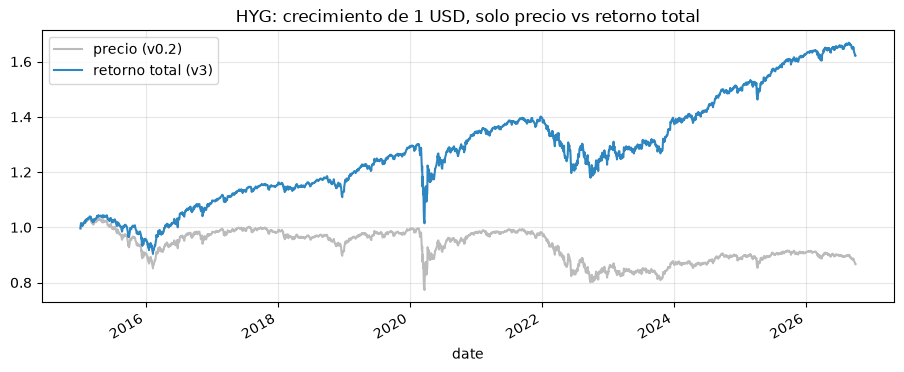

In [20]:
hyg = v3["HYG"].dropna(subset=["ret", "ret_price"])
growth = pd.DataFrame({"precio (v0.2)": np.exp(hyg["ret_price"].cumsum()),
                       "retorno total (v3)": np.exp(hyg["ret"].cumsum())})
ax = growth.plot(color=["#bbbbbb", "#2e86c1"])
ax.set_title("HYG: crecimiento de 1 USD, solo precio vs retorno total")
plt.show()

## 4 · Portafolio: por qué el VaR al 5 % casi no cambió

En el portafolio cambiaron tres cosas a la vez. Para separarlas, se calcula el mismo portafolio (pesos iguales) en cuatro escenarios, cambiando una cosa por vez:

| Escenario | Datos | Calendario cripto | Ventana |
|---|---|---|---|
| A | v0.2 | se descartan fines de semana | la de v0.2 |
| B | v3 | se descartan fines de semana | la de v0.2 |
| C | v3 | fin de semana sumado al lunes | la de v0.2 |
| D | v3 | fin de semana sumado al lunes | completa (lo que reporta el pipeline) |

- A → B: efecto de los datos (recorte, dividendos y fuente).
- B → C: efecto del calendario.
- C → D: efecto de la ventana. Coinbase tiene ETH desde 2016 y Yahoo desde finales de 2017.

In [21]:
def matrix(source: dict, col: str) -> pd.DataFrame:
    return pd.DataFrame({t: source[t][col] for t in TICKERS})


def summary(r: pd.Series) -> dict:
    return {"desde": r.index.min().date(), "hasta": r.index.max().date(), "dias": len(r),
            "VaR5": historical_var(r, 0.05), "CVaR5": historical_cvar(r, 0.05),
            "VaR1": historical_var(r, 0.01), "CVaR1": historical_cvar(r, 0.01),
            "max_dd": max_drawdown(r), "sharpe": sharpe_ratio(r)}


port_a = portfolio_returns(matrix(legacy, "ret"))
lo, hi = port_a.index.min(), port_a.index.max()

v3_ret = matrix(v3, "ret")
port_b = portfolio_returns(v3_ret.loc[lo:hi])
port_c = portfolio_returns(aggregate_crypto_to_equity_sessions(v3_ret).loc[lo:hi])
port_d = portfolio_returns(aggregate_crypto_to_equity_sessions(v3_ret))

scenarios = pd.DataFrame({"A v0.2": summary(port_a), "B v3 datos": summary(port_b),
                          "C + calendario": summary(port_c), "D + ventana": summary(port_d)}).T
scenarios

,desde,hasta,dias,VaR5,CVaR5,VaR1,CVaR1,max_dd,sharpe
A v0.2,2017-11-10,2026-08-31,2211,0.0203,0.0304,0.0359,0.0470,0.4094,0.7537
B v3 datos,2017-11-10,2026-08-31,2211,0.0202,0.0314,0.0364,0.0510,0.4160,0.7378
C + calendario,2017-11-10,2026-08-31,2211,0.0199,0.0320,0.0381,0.0542,0.4186,0.7985
D + ventana,2016-05-20,2026-10-02,2607,0.0191,0.0303,0.0354,0.0515,0.4186,1.0379


**Cómo leer la tabla.** Mira primero las columnas `VaR1` y `CVaR1` entre A y B: ahí aparece el recorte. Después mira `VaR5` entre C y D, que muestra el efecto de la ventana.

El `sharpe` de B en adelante incluye dividendos. La fila D debe coincidir con `artifacts/risk/portfolio_summary.csv`; si no coincide, hay que revisar el pipeline.

## 5 · Días marcados

Todos los días con algún flag, para revisarlos uno por uno. Un outlier confirmado en las noticias (crash del COVID, resultados trimestrales) es un **evento real** y se conserva. Un error del proveedor se vería como un salto que no aparece en ninguna otra fuente.

In [22]:
flag_cols = [c for c in next(iter(v3.values())).columns if c.startswith("flag_") and c != "flag_any"]
flagged = []
for t in TICKERS:
    d = v3[t]
    hit = d[d["flag_any"]]
    for date, row in hit.iterrows():
        flagged.append({"ticker": t, "fecha": date.date(), "ret_%": 100 * row["ret"],
                        "flags": ", ".join(c.replace("flag_", "") for c in flag_cols if row[c])})
flagged = pd.DataFrame(flagged).sort_values(["fecha", "ticker"])
print(f"{len(flagged)} dias marcados en {flagged['ticker'].nunique()} tickers")
flagged.groupby("flags").size().rename("dias").to_frame()

149 dias marcados en 18 tickers


,dias
flags,
outlier,132
"outlier, jump_no_action",4
stale,13


In [23]:
by_date = flagged.groupby("fecha")["ticker"].count().sort_values(ascending=False).head(10)
print("Fechas con mas tickers marcados a la vez (eventos de mercado, no errores de un proveedor):")
by_date.to_frame("tickers_marcados")

Fechas con mas tickers marcados a la vez (eventos de mercado, no errores de un proveedor):


,tickers_marcados
fecha,
2020-03-16,13
2020-03-12,9
2020-03-13,7
2025-04-09,7
2020-03-09,6
2020-03-18,5
2020-03-24,5
2018-02-05,3
2020-03-11,3


### Detalle de ETH-USD

ETH tiene precios congelados (`stale`) y fechas faltantes, ambos de los primeros años en Coinbase, con poco volumen. Aquí se ve cada caso con su volumen, para decidir si se acepta o se excluye ese tramo de la historia.

In [24]:
eth = v3["ETH-USD"]
stale_dates = eth.index[eth["flag_stale"]]
context = sorted({d + pd.Timedelta(days=k) for d in stale_dates for k in (-2, -1, 0, 1)} & set(eth.index))
display(eth.loc[context, ["open", "high", "low", "close", "volume", "ret", "flag_stale"]])

expected = expected_dates("ETH-USD", eth.index.min(), eth.index.max())
missing = expected.difference(eth.index)
print("Fechas faltantes en ETH-USD:", [d.date() for d in missing])

,open,high,low,close,volume,ret,flag_stale
date,,,,,,,
2016-08-17,11.1800,11.2600,10.6900,10.8200,"40,056.8272",-0.0327,False
2016-08-18,10.8200,11.0600,10.7600,10.7700,"35,781.1946",-0.0046,False
2016-08-19,10.7700,10.8600,10.6500,10.7700,"29,172.2477",0.0000,True
2016-08-20,10.7700,11.3700,10.7000,11.3000,"35,237.8312",0.0480,False
2016-10-14,11.8800,12.0700,11.8400,11.9200,"36,671.1233",0.0042,False
2016-10-15,11.9100,11.9700,11.7800,11.9500,"21,325.8737",0.0025,False
2016-10-16,11.9600,12.0500,11.9000,11.9500,"16,434.5195",0.0000,True
2016-10-17,11.9500,11.9900,11.8300,11.9600,"29,086.8662",0.0008,False
2016-12-18,7.8400,7.9700,7.6900,7.9200,"21,241.0808",0.0089,False


Fechas faltantes en ETH-USD: [datetime.date(2016, 5, 21), datetime.date(2016, 5, 22)]


## Conclusiones

Completa esta sección con los números de las tablas de arriba. Así queda escrita con tus palabras, que es lo que vas a tener que defender.

1. **Recorte de v0.2:** ¿cuánto subestimaba el CVaR al 1 % en promedio y en el peor caso? ¿Por qué el VaR al 5 % casi no cambia?
2. **Dividendos:** ¿qué activos perdían más rendimiento y cuánto al año?
3. **Portafolio:** de la diferencia entre A y D, ¿cuánto se explica por los datos, cuánto por el calendario y cuánto por la ventana?
4. **Flags:** ¿hay algún día marcado que no corresponda a un evento real conocido? ¿Se acepta el tramo inicial de ETH?

**Siguiente paso:** contrastar los días marcados con una segunda fuente para separar automáticamente los eventos confirmados de los posibles errores del proveedor.